# Can a Model Catch Faked Research Images?
## Finding copy-move forgeries in scientific figures

**Author:** Zied Raboudi

**Course:** COSC 4358 Computer Vision, Fall 2026

### Project overview
Some research papers contain faked images. One common trick is a **copy-move forgery**:
someone copies part of an image, like a cell or a band on a western blot, and pastes it
somewhere else in the same image. These edits are hard to catch by eye because the pasted
part is a real piece of the same picture.

In this project I built a system that takes a research image and returns a **mask** that
shows which parts were copied. White means copied and black means clean. If the mask is
empty, the image is called real. The system has two parts that work together:
1. **A U-Net segmentation model** with an EfficientNet-B4 encoder, the part that reads the
   image. It gives every pixel a score for how likely it is to be copied, plus one score for
   whether the whole image is fake.
2. **Keypoint matching** with SIFT or DISK. It finds spots that appear twice in the same image,
   which is exactly what a copy-move forgery leaves behind.

```
image --> U-Net --> pixel scores --> pass mark, cleaning, fake check --> U-Net mask --+
  |                                                                                   +--> final mask
  +-----> keypoint matching -----------------------------------------> keypoint mask --+
```

The **pass mark** is the score a pixel needs to count as copied. **Cleaning** erases tiny white
specks from the mask. The **fake check** throws the U-Net mask away when the model thinks the
whole image is real.

**Results at a glance.** On 519 test images that were never used for training or for choosing
settings, the full system scores 0.736 out of 1. It catches 80% of the fake images and wrongly
flags 6% of the real ones. Calling every image real would score 0.459, because 238 of the 519
test images are real.

### Dataset
- Kaggle competition **Recod.ai/LUC Scientific Image Forgery Detection**
- 5,176 images: 2,377 real and 2,799 fake, including the extra fakes from the supplemental set
- Images range from 98 to 4,417 pixels on their longest side
- The copied part covers a median of only 2.8% of a fake image
- Split by case ID into 4,142 training, 515 validation and 519 test images

### Changes from my proposal and why
The core of my proposal stayed the same: a U-Net with a pretrained encoder, trained with BCE
and Dice loss, which section 7 explains, followed by a pass mark and removal of small spots.
While working on it I made
several changes based on feedback from my professor, on what the top teams in the competition
did, and on what my own experiments showed.

**A per-image score.** My proposal listed the official competition metric together with the
mask overlap F1 on fake images, the share of fakes caught, the false alarm rate and a baseline
that calls every image real. I measure all of these except the official metric. It scores each
copied region separately, and my model produces one merged mask per image, so I score each
image instead. A real image gets
1 if nothing is marked and 0 otherwise. A fake image gets the overlap F1 between my mask and
the true mask, which is 1 for a perfect match and 0 for no overlap.

**A second output for the whole image.** With this score, marking anything on a real image costs
the full point for that image. So I added a second output to the U-Net that predicts whether the
whole image is fake, and the mask is only kept when that score is high enough. This is the fake
check, and its job is to keep false alarms low.

**A regularization study.** Regularization means techniques that keep a model from memorizing
its training images. My professor asked me to test it, so at my progress update I compared three
versions of the model. The results are in the table below.

**Keypoint matching with two methods.** My professor suggested adding keypoints and later
trying a second keypoint method, so I compare SIFT, a classic hand-designed method, with DISK,
a neural network that was trained to find keypoints. My proposal mentioned LightGlue, a learned matcher that
pairs up points between two different images. Here an image has to be matched against itself,
and I expected LightGlue to simply pair every point with itself. I did not have time to adapt it,
so I kept simple nearest neighbor matching and used DISK as the learned part.

**EfficientNet-B4 instead of DINOv2.** I proposed DINOv2 as a stronger encoder, but it needs a
custom decoder. EfficientNet-B4 is also much stronger than the ResNet-34 encoder I started with and works with
the same
U-Net code, which fit my time and GPU budget.

**Augmentation.** My first EfficientNet-B4 run overfit. Its training loss kept falling while
its validation loss stayed flat from about epoch 4, and its validation score stopped rising
after epoch 12. So I added random flips and
rotations during training, and with them the validation loss kept improving for much longer.

**Ideas from the top teams.** For SIFT I boost the contrast with CLAHE, a standard contrast
boost that the 3rd place team used. I also use a much lower contrast threshold so SIFT finds
points on faint western blots, like the 2nd place team did.

**Two smaller additions.** Keypoint matching can find about three copied regions per image
instead of one. I also tried a flip test, where the model looks at mirrored copies of each
image and the answers are averaged.

**A separate test set.** I proposed an 80/20 split. I switched to 80/10/10 so that validation
images pick the settings and a separate test set gives the final numbers.

**Something that did not work.** I tried 768 by 768 images to keep more detail in small copies.
It ran out of memory on Kaggle and was not ahead of the 512 run when it stopped, so I
kept 512.

#### Regularization study from my progress update
At my progress update I trained three ResNet-34 U-Nets for 10 epochs each, using the version
of the code I had in October. L2 weight decay keeps the weights small, and dropout switches
off random units during training.

| Model | Regularization | Best validation score |
|---|---|---|
| A | None | 0.635 |
| B | L2 weight decay of 0.05 | **0.638** |
| C | L2, augmentation and dropout of 0.3 | 0.631 |

The three scores were very close and none of the models overfit in 10 epochs. Model B was
slightly ahead, so I kept its L2 setup and trained for longer. Augmentation only became useful
later, once I trained a bigger model for more epochs.

These three scores cannot be compared exactly with the ones later in this notebook, because
the October code ignored marks smaller than 100 pixels when it scored the validation images.

## 1. Setup
Install the two libraries that Kaggle does not include and import everything the notebook uses.

In [1]:
!pip install -q segmentation-models-pytorch kornia

import glob
import hashlib
import json
import multiprocessing as mp
import os
import random
import sys
import time
import warnings
from collections import Counter

import albumentations as A
import cv2
import kornia.feature as KF
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import segmentation_models_pytorch as smp
import torch
import torch.nn as nn
from albumentations.pytorch import ToTensorV2
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
from torch.utils.data import DataLoader, Dataset

warnings.filterwarnings("ignore")   # hide library warnings
cv2.setNumThreads(0)   # OpenCV threads can freeze data loading on Kaggle

## 2. Settings
The main training settings are kept in one place so they are easy to find and change.

In [2]:
SIZE = 512           # every image is resized to 512 by 512 pixels
EPOCHS = 30          # the most passes over the training images
PATIENCE = 12        # stop early after 12 epochs with no improvement
MAX_MINUTES = 180    # time limit for training one model
MAX_RAM_GB = 22      # stop training before Kaggle runs out of memory
BLOCK = 5            # epochs trained in each separate process
BATCH = 8            # images per GPU in each training step
LR = 3e-4            # learning rate: how big each weight change is
WEIGHT_DECAY = 0.05  # L2 regularization from model B

The next cell checks for a GPU, fixes the random seeds and sets one colorblind-safe palette
for all the plots. The notebook stops right away if no GPU is turned on.

In [3]:
# count the GPUs without starting CUDA in this process. The training
# processes in section 9 are copies of this one and start CUDA themselves
N_GPU = torch.cuda.device_count()
device = "cuda" if N_GPU > 0 else "cpu"
assert device == "cuda", (
    "No GPU. Set Accelerator to GPU T4 x2 in the Settings panel.")
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# a colorblind-safe palette for every plot
PALETTE = sns.color_palette("colorblind")
sns.set_theme(style="whitegrid", palette=PALETTE, font_scale=1.15)
print("Device:", device, "| GPUs:", N_GPU)

Device: cuda | GPUs: 2


## 3. Loading the data
I build a list of every image with its mask file and its label, where 0 means real and 1 means fake.
The supplemental images are extra fakes that come with the competition.

In [4]:
# the competition folder is the one that holds the train_masks folder
base = os.path.dirname(
    glob.glob("/kaggle/input/**/train_masks", recursive=True)[0])


def stem(path):
    """Return the file name without .png, which is the case ID."""
    return os.path.splitext(os.path.basename(path))[0]


def mask_for(img_path, mask_dir):
    """Return the mask file for an image, or None if it has no mask."""
    path = os.path.join(base, mask_dir, stem(img_path) + ".npy")
    return path if os.path.exists(path) else None


def find(pattern):
    """Return every file in the data folder that matches a pattern."""
    return sorted(glob.glob(f"{base}/{pattern}", recursive=True))


# each item is an image path, a mask path or None, and a label 0 or 1
items = []
for path in find("train_images/authentic/**/*.png"):
    items.append((path, None, 0))
for path in find("train_images/forged/**/*.png"):
    items.append((path, mask_for(path, "train_masks"), 1))
for path in find("supplemental_images/**/*.png"):
    items.append((path, mask_for(path, "supplemental_masks"), 1))

# a fake image is only useful if it has a mask
items = [item for item in items if item[2] == 0 or item[1] is not None]
print("Real images:", sum(item[2] == 0 for item in items))
print("Fake images:", sum(item[2] == 1 for item in items))

Real images: 2377
Fake images: 2799


## 4. Cleaning the data and preparing the images
For training, each image is read once, resized to 512 by 512 and kept in memory, so training
never has to reopen files. Some masks have a separate layer for each copied region, so the
first function merges the layers into one mask.

While loading, I also check the data. Images that cannot be opened, fake images with an empty
mask and exact duplicates are removed, and masks whose size does not match their image are
fixed. The report further down shows that this dataset had none of these problems, so nothing
had to be removed or fixed.

In [5]:
def read_mask(mask_path, h, w, report):
    """Load a mask, merge its layers and resize it to match its image."""
    mask = np.load(mask_path)
    if mask.ndim == 3:
        # the shortest axis is the one that holds the layers
        layer_axis = int(np.argmin(mask.shape))
        mask = mask.max(axis=layer_axis)
    if mask.shape != (h, w):
        mask = cv2.resize(mask.astype(np.uint8), (w, h),
                          interpolation=cv2.INTER_NEAREST)
        report["mask size did not match its image - fixed"] += 1
    return (mask > 0).astype(np.uint8)

The loop below reads every image and its mask, resizes them and runs the checks.

In [6]:
N = len(items)
IMGS = np.zeros((N, SIZE, SIZE, 3), np.uint8)
MASKS = np.zeros((N, SIZE, SIZE), np.uint8)
LABELS = np.array([label for _, _, label in items])
# the list keep holds the images that pass the checks, sides holds their
# longest sides and copied holds the copied area of each fake as a percent
report, seen, keep, sides, copied = Counter(), set(), [], [], []

start = time.time()
for k, (path, mask_path, label) in enumerate(items):
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None:
        report["image could not be opened - removed"] += 1
        continue
    h, w = img.shape[:2]
    rgb = img[:, :, ::-1]            # OpenCV reads BGR, the model wants RGB
    IMGS[k] = cv2.resize(rgb, (SIZE, SIZE), interpolation=cv2.INTER_AREA)
    if mask_path is not None:
        mask = read_mask(mask_path, h, w, report)
        MASKS[k] = cv2.resize(mask, (SIZE, SIZE),
                              interpolation=cv2.INTER_NEAREST)
        if MASKS[k].sum() == 0:
            report["fake image with an empty mask - removed"] += 1
            continue
        copied.append(mask.mean() * 100)
    # two images with the same fingerprint are identical after resizing
    fingerprint = hashlib.md5(IMGS[k].tobytes()).hexdigest()
    if fingerprint in seen:
        report["exact duplicate - removed"] += 1
        continue
    seen.add(fingerprint)
    keep.append(k)
    sides.append(max(h, w))
print(f"Loaded {N} images in {time.time() - start:.0f} seconds")

Loaded 5176 images in 367 seconds


The report lists every problem that was found and sums up the images that were kept.

In [7]:
print("DATA CLEANING REPORT")
for problem, count in report.items():
    print(f"  {count:5d}  {problem}")
if not report:
    print("  no problems found")

n_real = sum(LABELS[keep] == 0)
n_fake = sum(LABELS[keep] == 1)
print(f"Kept {len(keep)} of {N} images: {n_real} real and {n_fake} fake")
print(f"Longest image side: {min(sides)} to {max(sides)} pixels")
print(f"Copied area: median {np.median(copied):.1f}% of a fake image")

DATA CLEANING REPORT
  no problems found
Kept 5176 of 5176 images: 2377 real and 2799 fake
Longest image side: 98 to 4417 pixels
Copied area: median 2.8% of a fake image


### Plot 1: what the data looks like
The left chart shows that image sizes vary a lot, which is why every image is resized to one
size. Its fake bars are stacked on top of the real bars, so the full height of a bar counts all
the images of that size. They are striped so the two groups can be told apart without color. The right
chart shows that the copied part is usually a small share of the image, so the model has to
find small targets. That chart stops at 40% to keep the small values readable, so a fake with
a larger copied area is not drawn.

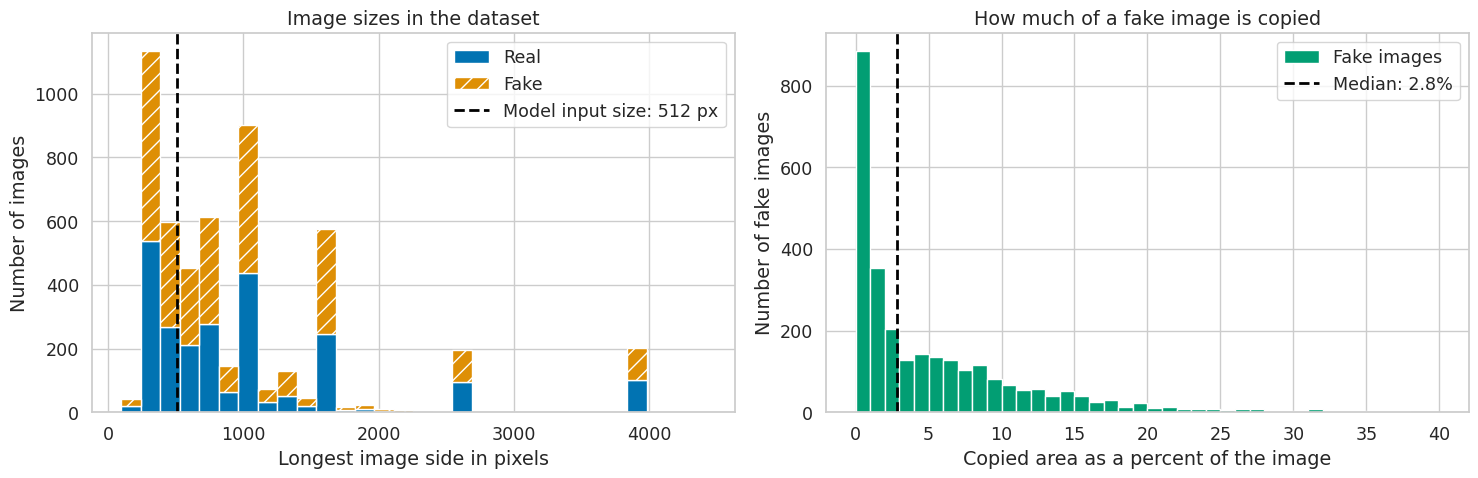

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

real_sides = [s for s, k in zip(sides, keep) if LABELS[k] == 0]
fake_sides = [s for s, k in zip(sides, keep) if LABELS[k] == 1]
_, _, bars = ax1.hist([real_sides, fake_sides], bins=30, stacked=True,
                      color=PALETTE[:2], edgecolor="white",
                      label=["Real", "Fake"])
for bar in bars[1]:
    bar.set_hatch("//")          # stripes, so color is not the only cue
ax1.axvline(SIZE, color="black", ls="--", lw=2,
            label=f"Model input size: {SIZE} px")
ax1.set_title("Image sizes in the dataset")
ax1.set_xlabel("Longest image side in pixels")
ax1.set_ylabel("Number of images")
ax1.legend()

median = np.median(copied)
# the chart stops at 40 percent, so larger copies are not drawn
ax2.hist(copied, bins=40, range=(0, 40), color=PALETTE[2], edgecolor="white",
         label="Fake images")
ax2.axvline(median, color="black", ls="--", lw=2,
            label=f"Median: {median:.1f}%")
ax2.set_title("How much of a fake image is copied")
ax2.set_xlabel("Copied area as a percent of the image")
ax2.set_ylabel("Number of fake images")
ax2.legend()

plt.tight_layout()
plt.savefig("plot1_data.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Splitting the data
I split the images into 80% for training, 10% for validation and 10% for testing.
The split is done by case ID because a real image and its fake version share the same ID.
Keeping them together means the model is never tested on a picture it already saw in training.

- **Training images** are what the model learns from.
- **Validation images** pick the best epoch, the pass mark, the smallest spot that is kept, the
  fake check, the number of matches a keypoint mask needs and the keypoint method.
- **Test images** are never used for training, for picking the epoch or for choosing settings.
  They are only scored for the final numbers.

In [9]:
# shuffle the case IDs once, then cut the list at 80% and at 90%
ids = sorted({stem(path) for path, _, _ in items})
random.Random(42).shuffle(ids)
cut1 = int(0.8 * len(ids))
cut2 = cut1 + (len(ids) - cut1) // 2
train_ids = set(ids[:cut1])
val_ids = set(ids[cut1:cut2])
test_ids = set(ids[cut2:])

train_idx = [k for k in keep if stem(items[k][0]) in train_ids]
val_idx = [k for k in keep if stem(items[k][0]) in val_ids]
test_idx = [k for k in keep if stem(items[k][0]) in test_ids]

for name, idx in [("train", train_idx), ("validation", val_idx),
                  ("test", test_idx)]:
    n_real = sum(LABELS[idx] == 0)
    n_fake = sum(LABELS[idx] == 1)
    print(f"{name:11s} {len(idx):5d} images: {n_real} real and {n_fake} fake")

train        4142 images: 1904 real and 2238 fake
validation    515 images: 235 real and 280 fake
test          519 images: 238 real and 281 fake


## 6. Feeding images to the model
During training, each image gets random flips and 90 degree turns, and its mask gets exactly the
same change so the two still line up. This is the augmentation described at the start.

`Normalize` scales the pixels the way the pretrained encoder expects, and `ToTensorV2` turns
each picture into a PyTorch tensor.

In [10]:
# the plain transform for validation and test, with no augmentation
to_tensor = A.Compose([A.Normalize(), ToTensorV2()])
# the training transform, where random flips and quarter turns come first
augment = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.Normalize(),
    ToTensorV2(),
])

### The dataset class
The dataset class hands PyTorch one image at a time, together with its mask and its label.

In [11]:
class ForgeryData(Dataset):
    """Give PyTorch one image with its mask and label at a time."""

    def __init__(self, idx, transform):
        """Remember which images to serve and how to transform them."""
        self.idx = idx
        self.transform = transform

    def __len__(self):
        """The number of images in this set."""
        return len(self.idx)

    def __getitem__(self, i):
        """Return one image, its mask and its label as tensors."""
        k = self.idx[i]
        out = self.transform(image=IMGS[k], mask=MASKS[k])
        image = out["image"]
        # add a channel axis so the mask has the shape of the model output
        mask = out["mask"][None].float()
        label = torch.tensor([float(LABELS[k])])
        return image, mask, label

### The data loader
The `DataLoader` serves the images in batches. It uses no extra loader processes, because the
images are already in memory and loading them is fast.

In [12]:
def make_loader(idx, shuffle, transform=to_tensor):
    """Serve the images in batches of BATCH images per GPU.

    The training loader shuffles and drops the last short batch.
    """
    batch_size = BATCH * max(1, N_GPU)
    return DataLoader(ForgeryData(idx, transform), batch_size=batch_size,
                      shuffle=shuffle, drop_last=shuffle, num_workers=0)

A fixed sample of training images, as large as the validation set, is used to measure the
training loss after each epoch.

In [13]:
# a sample of training images, used to measure training loss after each epoch
check_idx = random.Random(0).sample(train_idx,
                                    min(len(train_idx), len(val_idx)))

## 7. Loss function and predictions
The loss tells the model how wrong it is. It adds up three parts:
- **BCE**, short for binary cross-entropy, checks every pixel on its own.
- **Dice** checks how well the predicted shape overlaps the true shape. This matters because
  copied regions are small, and BCE alone would reward a model that marks almost nothing.
- **BCE at half weight** checks the real or fake answer for the whole image.

In [14]:
bce = nn.BCEWithLogitsLoss()
dice = smp.losses.DiceLoss(mode="binary")


def loss_fn(seg, cls, y, label):
    """Mask loss plus a half-weight loss on the real or fake answer."""
    return bce(seg, y) + dice(seg, y) + 0.5 * bce(cls, label)

### Making predictions
When predicting, sigmoid squashes each raw score to a value between 0 and 1. With the flip test
turned on, the model also looks at the image mirrored left to right and top to bottom. Each
answer is flipped back and the three answers are averaged.

In [15]:
@torch.no_grad()
def predict(model, idx, tta=False, keep=True):
    """Return pixel scores, fake scores and the average loss for some images.

    With tta=True the scores are averaged over the image and its two
    mirrored copies. This is the flip test.
    With keep=False the scores are not stored and come back as None,
    which saves memory in training.
    """
    model.eval()
    probs, fake, losses = [], [], []
    for x, y, label in make_loader(idx, shuffle=False):
        x, y, label = x.to(device), y.to(device), label.to(device)
        # autocast uses 16 bit numbers where it is safe, which is faster
        with torch.autocast(device_type="cuda", enabled=device == "cuda"):
            seg, cls = model(x)
            losses.append(loss_fn(seg, cls, y, label).item())
            p = torch.sigmoid(seg.float())
            f = torch.sigmoid(cls.float())
            if tta:
                # dim 3 flips left to right and dim 2 flips top to bottom
                for dim in (3, 2):
                    seg2, cls2 = model(torch.flip(x, dims=[dim]))
                    # flip the answer back so it lines up with the image
                    p = p + torch.flip(torch.sigmoid(seg2.float()), dims=[dim])
                    f = f + torch.sigmoid(cls2.float())
                p, f = p / 3, f / 3    # the average of the 3 answers
        if keep:
            # float16 halves the memory these scores take
            probs.append(p[:, 0].cpu().numpy().astype(np.float16))
            fake.append(f[:, 0].cpu().numpy())
    probs = np.concatenate(probs) if keep else None
    fake = np.concatenate(fake) if keep else None
    return probs, fake, float(np.mean(losses))

## 8. How I measure the results
- **Score:** a real image scores 1 if nothing is marked and 0 if anything is marked. A fake image
  scores the overlap F1 between my mask and the true mask. The score is the average over all
  images, and higher is better.
- **Overlap F1:** twice the number of pixels that are white in both masks, divided by the white
  pixels of the two masks added together. It is 1 for a perfect match and 0 for no overlap. It
  is the same measure as the Dice score.
- **Fakes caught:** the share of fake images where something is marked.
- **False alarms:** the share of real images that are marked by mistake.
- **Mask F1:** the average overlap F1 over the fake images only. A fake that is missed
  completely counts as 0.

The last function in the cell makes the plain masks that are used to score the model during
training.

In [16]:
def image_score(k, mask):
    """Score one image: 1 or 0 for a real image, the overlap F1 for a fake."""
    marked = mask.sum() > 0
    if LABELS[k] == 0:
        return 0.0 if marked else 1.0
    if not marked:
        return 0.0
    truth = MASKS[k] > 0
    # overlap F1: twice the shared pixels over the pixels of both masks
    return 2 * (mask & truth).sum() / (mask.sum() + truth.sum())


def score(idx, masks):
    """Score, fakes caught, false alarms and mask F1 for a set of images."""
    scores = np.array([image_score(k, m) for k, m in zip(idx, masks)])
    marked = np.array([m.sum() > 0 for m in masks])
    labels = LABELS[idx]
    return dict(score=scores.mean(),
                caught=marked[labels == 1].mean(),
                false_alarm=marked[labels == 0].mean(),
                f1=scores[labels == 1].mean())


def simple_masks(probs, fake):
    """Plain masks with the pass mark and the fake check both at 0.5.

    Used for the validation score in training and for the U-Net plain
    row of the results table.
    """
    return [(p > 0.5) & (f >= 0.5) for p, f in zip(probs, fake)]

## 9. The model: a U-Net with a second output
`smp.Unet` builds the U-Net. The **encoder** shrinks the image and picks out patterns like edges
and textures. It starts from weights pretrained on ImageNet, a large collection of everyday
photos, so it does not have to learn those patterns from scratch. The **decoder** grows the
result back to full size and gives every pixel a score. `aux_params` adds the second output, a
single score for whether the whole image is fake.

In [17]:
def build_model(encoder, pretrained=True):
    """A U-Net with two outputs: the mask and a fake score for the image."""
    return smp.Unet(
        encoder_name=encoder,
        encoder_weights="imagenet" if pretrained else None,
        in_channels=3,
        classes=1,
        aux_params=dict(classes=1, dropout=0.0),
    ).to(device)

A small helper reports how much memory the current process is using. The training log
prints it after every epoch.

In [18]:
def ram_gb():
    """How much RAM the current process is using right now, in GB."""
    # the second number in this file is the memory in use, counted in pages
    pages = int(open("/proc/self/statm").read().split()[1])
    return pages * os.sysconf("SC_PAGE_SIZE") / 1e9

### One epoch of training
Each training step runs a batch of images through the model, measures the loss, and lets the
optimizer nudge every weight in the direction that lowers it. The optimizer is AdamW and it is
created in the training loop below. Its `weight_decay` works like L2 regularization and keeps
the weights from growing too large.

In [19]:
def train_one_epoch(net, loader, opt, scaler):
    """One pass over all the training images."""
    net.train()
    for x, y, label in loader:
        x, y, label = x.to(device), y.to(device), label.to(device)
        opt.zero_grad()
        with torch.autocast(device_type="cuda", enabled=device == "cuda"):
            seg, cls = net(x)                    # forward pass: make a guess
            loss = loss_fn(seg, cls, y, label)   # how wrong was the guess
        scaler.scale(loss).backward()            # backward pass: what to fix
        scaler.step(opt)                         # change the weights
        scaler.update()

### The training loop
After every epoch I check the model on the validation images and save it whenever the validation
score improves. The learning rate starts at 0.0003 and shrinks along a cosine curve, so the
changes get finer as training goes on. Training stops early if the score has not improved for
12 epochs, if training passes the time limit or if memory runs low. The best saved epoch is the one
that is kept.

The first cell holds small helpers: the file names, the random seeds and an empty training
record.

In [20]:
STATE = "/tmp/train_state.pt"     # all that is needed to continue training
PROGRESS = "/tmp/progress.json"   # the epoch lines and history as plain text


def set_seeds(seed):
    """Seed every random generator. Each block passes its own seed."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    # newer Albumentations versions keep their own random generator
    if hasattr(augment, "set_random_seed"):
        augment.set_random_seed(seed)


def new_state():
    """An empty training record, used when training starts at epoch 1."""
    # best is the top validation score, bad counts epochs without a new best
    return dict(hist={"train_loss": [], "val_loss": [], "val_score": []},
                lines=[], best=-1.0, bad=0, minutes=0.0, stop=False)

One full epoch trains the model, lowers the learning rate and then measures the training
loss, the validation loss and the validation score.

In [21]:
def run_epoch(net, loader, opt, sched, scaler):
    """Train for one epoch, then measure the losses and validation score."""
    train_one_epoch(net, loader, opt, scaler)
    sched.step()                      # lower the learning rate
    _, _, train_loss = predict(net, check_idx, keep=False)
    probs, fake, val_loss = predict(net, val_idx)
    val_score = score(val_idx, simple_masks(probs, fake))["score"]
    return dict(train_loss=train_loss, val_loss=val_loss,
                val_score=float(val_score))

The next function trains a block of epochs. A block is 5 epochs here, because memory use grew
with every epoch and a fresh process gives it back. This is explained right after the code.
After every epoch the function saves the full training state, which is the model, the
optimizer, the learning rate schedule, the scaler used for 16 bit training and the history so
far. That makes it possible to stop after any epoch and continue later from the saved weights
and settings.

In [22]:
def train_block(encoder, first, last):
    """Train epochs first to last, saving the training state every epoch."""
    set_seeds(42 + first)
    # only the first block starts from the ImageNet weights
    model = build_model(encoder, pretrained=first == 1)
    opt = torch.optim.AdamW(model.parameters(), lr=LR,
                            weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    scaler = torch.amp.GradScaler("cuda", enabled=device == "cuda")
    parts = dict(model=model, opt=opt, sched=sched, scaler=scaler)
    state = new_state()
    if first > 1:     # continue where the last block stopped
        state = torch.load(STATE, weights_only=False)
        for name, part in parts.items():
            part.load_state_dict(state[name])
    net = nn.DataParallel(model) if N_GPU > 1 else model     # use both GPUs
    loader = make_loader(train_idx, shuffle=True, transform=augment)

    for epoch in range(first, last + 1):
        start = time.time()
        result = run_epoch(net, loader, opt, sched, scaler)
        for key, value in result.items():
            state["hist"][key].append(value)
        note = ""
        if result["val_score"] > state["best"]:
            state["best"], state["bad"] = result["val_score"], 0
            note = "  <- best so far and saved"
            torch.save(model.state_dict(), f"model_{encoder}.pt")
        else:
            state["bad"] += 1
        state["minutes"] += (time.time() - start) / 60
        line = (f"Epoch {epoch:2d} | train loss {result['train_loss']:.3f}"
                f" | val loss {result['val_loss']:.3f}"
                f" | val score {result['val_score']:.3f}"
                f" | {state['minutes']:.0f} min | RAM {ram_gb():.1f} GB{note}")
        print(line, flush=True)
        state["lines"].append(line)
        # stop on no progress, on the time limit or when memory runs low
        state["stop"] = (state["bad"] >= PATIENCE
                         or state["minutes"] > MAX_MINUTES
                         or ram_gb() > MAX_RAM_GB)
        # add the weights of the model, optimizer, schedule and scaler
        state.update({name: part.state_dict() for name, part in parts.items()})
        torch.save(state, STATE)
        with open(PROGRESS, "w") as file:
            json.dump({key: state[key]
                       for key in ("lines", "stop", "hist")}, file)
        if state["stop"]:
            break

### Training in blocks to keep memory under control
On Kaggle, memory use grew by about 1 GB with every epoch of training, which is too much for
30 epochs. I could not pin down the exact cause, so I worked around it. The epochs are trained
in blocks of 5 and each block runs in its own process. When a block is done its process ends
and gives its memory back, and the next block continues from the saved training state.

The first two helpers check that a separate process can use the GPU and print the epoch lines
that the training process writes to its log file.

In [23]:
LOG = "/tmp/train_process.log"    # the training process writes its output here


def gpu_check():
    """A tiny job that shows a separate process can use the GPU."""
    torch.zeros(8, device=device).sum().item()


def show_epochs(position):
    """Print the new epoch lines in the log and return the new position."""
    with open(LOG) as log:
        log.seek(position)
        for line in iter(log.readline, ""):   # read to the end of the file
            if not line.endswith("\n"):     # this line is still being written
                break
            position = log.tell()
            if line.startswith("Epoch"):
                print(line.rstrip(), flush=True)
    return position

`run_apart` starts a job in its own process and waits for it. While it waits it prints
the finished epochs, and it stops the process if it runs past its time limit.

In [24]:
def run_apart(job, *args, minutes):
    """Run a job in its own process. Return True if it finished cleanly.

    The epoch lines it logs are printed while it runs. The process is
    stopped if it is still running after the given number of minutes.
    """
    def work():
        """What the new process does: log to a file, then run the job."""
        sys.stdout = sys.stderr = open(LOG, "a")
        torch.set_num_threads(1)     # avoids a freeze in forked processes
        job(*args)

    # make sure the log file exists, then start reading at its current end
    open(LOG, "a").close()
    position, deadline = os.path.getsize(LOG), time.time() + minutes * 60
    # a forked process starts as a copy of this one, images included. It can
    # use the GPU only because this process never started CUDA
    process = mp.get_context("fork").Process(target=work)
    process.start()
    while process.is_alive() and time.time() < deadline:
        process.join(10)
        position = show_epochs(position)   # print the finished epochs
    if process.is_alive():                # still running at the limit
        process.kill()
        process.join()
    if process.exitcode != 0:             # show why it failed
        with open(LOG) as log:
            print("A training process failed:\n"
                  + "".join(log.readlines()[-15:]))
    return process.exitcode == 0

### Putting the blocks together
This function runs the blocks one after another and returns the model from the best epoch
together with its training history. A block that fails gets one more try. If the separate
processes keep failing, the remaining epochs are trained in the notebook's own process as a
last resort.

In [25]:
def train_model(encoder):
    """Train in blocks, each in its own process.

    Return the model from the best epoch and its training history.
    """
    # remove files left by an earlier training run
    for old_file in (STATE, PROGRESS):
        if os.path.exists(old_file):
            os.remove(old_file)
    # first test that a separate process can reach the GPU at all
    failures = 0 if run_apart(gpu_check, minutes=3) else 1
    print("Training in separate processes" if failures == 0
          else "The GPU check failed once")
    done, stop, hist = 0, False, None
    while done < EPOCHS and not stop:
        # use separate processes until two tries in a row have failed
        if failures < 2:
            last = min(done + BLOCK, EPOCHS)
            # allow 8 minutes per epoch before a block counts as frozen
            worked = run_apart(train_block, encoder, done + 1, last,
                               minutes=BLOCK * 8)
            failures = 0 if worked else failures + 1
        else:                              # last resort: train in this process
            print("Training the remaining epochs in this process")
            train_block(encoder, done + 1, EPOCHS)
        # read the progress as plain text. Loading STATE would start CUDA here
        if os.path.exists(PROGRESS):
            with open(PROGRESS) as file:
                progress = json.load(file)
            done, stop, hist = (len(progress["lines"]), progress["stop"],
                                progress["hist"])
    if stop:
        print("Stopped early")
    model = build_model(encoder, pretrained=False)
    # go back to the weights of the best epoch
    model.load_state_dict(torch.load(f"model_{encoder}.pt"))
    return model, hist

## 10. Training and comparing models
I compare three models, all with L2 regularization since it was slightly ahead in my
regularization study:
1. **ResNet-34**, which is model B from my progress update trained for longer.
2. **EfficientNet-B4**, a stronger encoder.
3. **EfficientNet-B4 with augmentation**, the same encoder trained with random flips and turns.

The first two were trained in earlier runs on November 22 and 23, with an earlier version of
this code that had no augmentation. ResNet-34 ran for 20 epochs. EfficientNet-B4 had the
same budget of 30 epochs and the same learning rate schedule as the final model, but it stopped
at epoch 18 because early stopping waited only 6 epochs at that time. I copied their numbers from
those logs so the GPU time could go to the final model, which is trained right here.

In [26]:
# numbers copied from the logs of the earlier runs
hists = {"ResNet-34": {
    "train_loss": [1.323, 1.197, 1.195, 1.105, 1.043, 1.109, 1.022, 0.936,
                   0.895, 0.782, 0.782, 0.715, 0.617, 0.605, 0.560, 0.534,
                   0.504, 0.493, 0.476, 0.472],
    "val_loss": [0.917, 0.794, 0.771, 0.750, 0.721, 0.774, 0.738, 0.644, 0.643,
                 0.586, 0.604, 0.593, 0.557, 0.557, 0.564, 0.533, 0.540, 0.539,
                 0.551, 0.543],
    "val_score": [0.395, 0.456, 0.486, 0.430, 0.493, 0.514, 0.562, 0.577,
                  0.559, 0.602, 0.621, 0.606, 0.625, 0.628, 0.621, 0.629,
                  0.627, 0.632, 0.635, 0.632],
}, "EfficientNet-B4": {
    "train_loss": [1.024, 0.878, 0.653, 0.587, 0.561, 0.565, 0.517, 0.445,
                   0.513, 0.458, 0.383, 0.333, 0.334, 0.312, 0.293, 0.295,
                   0.265, 0.262],
    "val_loss": [0.688, 0.641, 0.533, 0.493, 0.494, 0.569, 0.487, 0.499, 0.539,
                 0.531, 0.493, 0.481, 0.480, 0.493, 0.505, 0.488, 0.494,
                 0.506],
    "val_score": [0.524, 0.557, 0.614, 0.649, 0.664, 0.648, 0.672, 0.674,
                  0.669, 0.675, 0.690, 0.706, 0.685, 0.696, 0.695, 0.694,
                  0.702, 0.692],
}}
for name, h in hists.items():
    print(f"{name}: best validation score {max(h['val_score']):.3f}")

ResNet-34: best validation score 0.635
EfficientNet-B4: best validation score 0.706


### Training the final model
This is the slowest part of the notebook, at about 4 minutes per epoch on two T4 GPUs.
Each line is one epoch, and the RAM column shows memory use dropping back down at the
start of every block of 5 epochs.

In [27]:
# only one model is trained in this run
ENCODERS = {"EfficientNet-B4 + augmentation": "efficientnet-b4"}
models = {}
for name, encoder in ENCODERS.items():
    print(f"\n=== {name} ===")
    t0 = time.time()
    models[name], hists[name] = train_model(encoder)
    print(f"{name} trained in {(time.time() - t0) / 60:.0f} minutes")


=== EfficientNet-B4 + augmentation ===
Training in separate processes
Epoch  1 | train loss 1.041 | val loss 0.712 | val score 0.504 | 4 min | RAM 9.0 GB  <- best so far and saved
Epoch  2 | train loss 0.759 | val loss 0.547 | val score 0.604 | 8 min | RAM 10.1 GB  <- best so far and saved
Epoch  3 | train loss 0.750 | val loss 0.538 | val score 0.650 | 11 min | RAM 11.3 GB  <- best so far and saved
Epoch  4 | train loss 0.701 | val loss 0.511 | val score 0.636 | 15 min | RAM 12.4 GB
Epoch  5 | train loss 0.671 | val loss 0.519 | val score 0.660 | 19 min | RAM 13.5 GB  <- best so far and saved
Epoch  6 | train loss 0.692 | val loss 0.516 | val score 0.655 | 22 min | RAM 8.9 GB
Epoch  7 | train loss 0.647 | val loss 0.542 | val score 0.665 | 26 min | RAM 10.1 GB  <- best so far and saved
Epoch  8 | train loss 0.712 | val loss 0.576 | val score 0.668 | 30 min | RAM 11.2 GB  <- best so far and saved
Epoch  9 | train loss 0.565 | val loss 0.477 | val score 0.690 | 33 min | RAM 12.3 GB  <-

### Plot 2: training loss and validation loss
A model is overfitting when its training loss keeps falling while its validation loss stops
improving. The middle chart shows this for EfficientNet-B4 without augmentation. Its validation
loss is flat from about epoch 4 while its training loss keeps falling, and its validation score
stops rising after epoch 12. With augmentation, in the right chart, the validation loss keeps trending down
until about epoch 27. The star marks the epoch that was kept for each model, which is the one
with the best validation score. The three charts share the loss axis on the left and cover 20,
18 and 30 epochs.

The two curves should be compared by their shape and not by the gap between them. In the early
epochs the validation loss sits below the training loss, partly because of how it is measured. The validation images are served in order
with the real images first, and the Dice part of the loss counts as zero for a batch that has
no copied pixels.

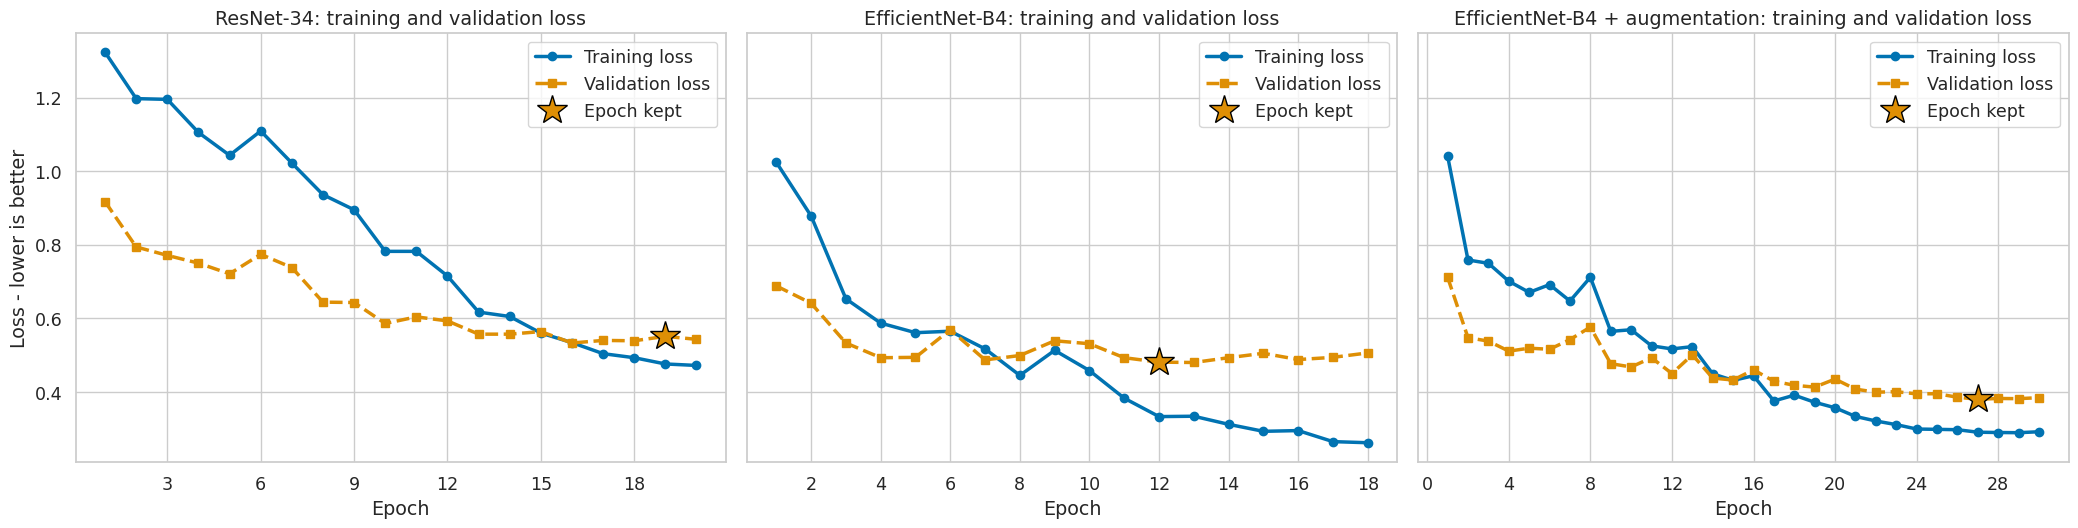

In [28]:
fig, axes = plt.subplots(1, len(hists), figsize=(21, 5.5), sharey=True,
                         squeeze=False)
axes = axes[0]
for ax, (name, h) in zip(axes, hists.items()):
    epochs = np.arange(1, len(h["train_loss"]) + 1)
    # the epoch kept is the one with the highest validation score
    best = int(np.argmax(h["val_score"]))
    ax.plot(epochs, h["train_loss"], "o-", color=PALETTE[0], lw=2.5,
            label="Training loss")
    ax.plot(epochs, h["val_loss"], "s--", color=PALETTE[1], lw=2.5,
            label="Validation loss")
    ax.plot(best + 1, h["val_loss"][best], "*", ms=22, color=PALETTE[1],
            mec="black", label="Epoch kept")
    ax.set_title(f"{name}: training and validation loss")
    ax.set_xlabel("Epoch")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend()
axes[0].set_ylabel("Loss - lower is better")
plt.tight_layout()
plt.savefig("plot2_loss.png", dpi=150, bbox_inches="tight")
plt.show()

### Plot 3: validation score after each epoch
This plot compares the three models on the validation images. Each model has its own line style
and marker, and the lines end at different epochs because the runs had different lengths. The
dotted line is the best score from my regularization study at the progress update. That line
was measured with my October scoring, which ignored marks under 100 pixels, so it is only a
rough reference. This is the likely reason ResNet-34 ends just below it even though it trained
for longer. From epoch 5 on, both EfficientNet-B4 models stay above the best ResNet-34 score
of 0.635.

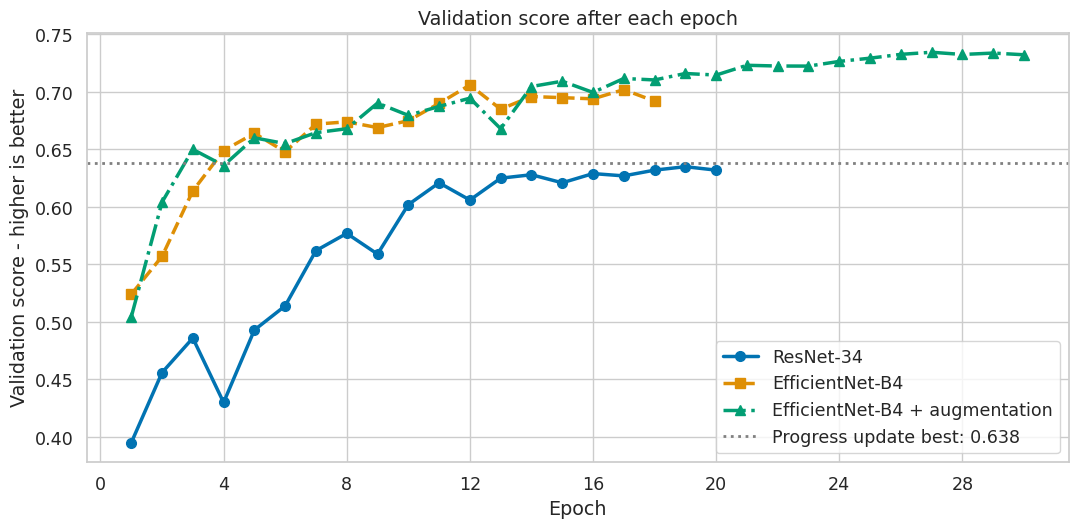

In [29]:
fig, ax = plt.subplots(figsize=(11, 5.5))
line_styles = [("o-", PALETTE[0]), ("s--", PALETTE[1]), ("^-.", PALETTE[2])]
for (name, h), (style, color) in zip(hists.items(), line_styles):
    epochs = np.arange(1, len(h["val_score"]) + 1)
    ax.plot(epochs, h["val_score"], style, color=color, lw=2.5, ms=7,
            label=name)
ax.axhline(0.638, color="gray", ls=":", lw=2,
           label="Progress update best: 0.638")
ax.set_title("Validation score after each epoch")
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation score - higher is better")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.legend()
plt.tight_layout()
plt.savefig("plot3_val_score.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Predictions from the best model
From here on I use the model trained in this notebook, which has the best validation score of
the three. I predict on the validation and test images with the flip test, and also once on the
test images without it, to see whether the flip test helps.

In [30]:
# pick the trained model with the highest validation score
best_name = max(models, key=lambda name: max(hists[name]["val_score"]))
best_model = models[best_name]
print("Best model:", best_name)

val_probs, val_fake, _ = predict(best_model, val_idx, tta=True)
test_probs, test_fake, _ = predict(best_model, test_idx, tta=True)
test_probs_plain, test_fake_plain, _ = predict(best_model, test_idx, tta=False)

Best model: EfficientNet-B4 + augmentation


## 12. Keypoint matching
A copy-move forgery means the same patch shows up twice, and keypoint matching looks for that
directly. Nothing is trained here. SIFT is hand-designed and DISK comes already trained. The
method works in four steps:
1. **Find keypoints**, which are distinctive spots like corners. Each one gets a descriptor, a
   list of numbers that describes how the spot looks.
2. **Compare** every keypoint with every other keypoint in the same image. A match is kept only
   if it is clearly better than the second best match and the two points are more than 20 pixels apart.
3. **Keep real copies with RANSAC.** A pasted patch moves as one piece. RANSAC tries out many
   possible moves, each one a shift with a turn and a resize, and keeps the move that the most
   pairs agree on. The pairs that fit it form one copied region. The search then runs again on
   the leftover pairs, up to six times in all. A copy usually shows up twice, once in each
   direction, so this finds about three copied regions in one image.
4. **Draw the mask** as the tightest outline around the kept points on both sides, filled in and
   grown a little.

I compare two ways of finding keypoints, **SIFT** and **DISK**. Steps 2 to 4 are the same for both.

In [31]:
def self_match(pts, desc, ratio):
    """Step 2: find pairs of points in one image that look the same."""
    src, dst = [], []
    # ask for 3 neighbors because the nearest one is the point itself
    for match in cv2.BFMatcher().knnMatch(desc, desc, k=3):
        # leave out the match of a point with itself
        others = [m for m in match if m.trainIdx != m.queryIdx]
        if len(others) < 2:
            continue
        best, second = others[0], others[1]
        p, q = pts[best.queryIdx], pts[best.trainIdx]
        clearly_best = best.distance < ratio * second.distance
        far_apart = np.hypot(p[0] - q[0], p[1] - q[1]) > 20
        if clearly_best and far_apart:
            src.append(p)
            dst.append(q)
    return np.float32(src), np.float32(dst)


def find_regions(src, dst, max_tries=6):
    """Step 3: find a copied region with RANSAC, then search what is left."""
    regions = []
    # a copy usually shows up twice, as A to B and B to A, so 6 tries
    # find about 3 copies
    for _ in range(max_tries):
        if len(src) < 4:
            break
        # find the one shift, turn and resize that the most pairs agree on.
        # a pair agrees if it lands within 5 pixels of where the move puts it
        M, inliers = cv2.estimateAffinePartial2D(src, dst, method=cv2.RANSAC,
                                                 ransacReprojThreshold=5)
        need = 4 if not regions else 8   # extra regions need more points
        if M is None or inliers.sum() < need:
            break
        hit = inliers.ravel() == 1       # the pairs that fit this region
        regions.append((src[hit], dst[hit]))
        src, dst = src[~hit], dst[~hit]  # search the matches that are left
    return regions

### Drawing the keypoint mask
For every region found, the outline is drawn around the matched points on both the original and
the copy. The function also returns how many pairs matched, which later decides whether the
mask is trusted.

In [32]:
def keypoint_mask(pts, desc, h, w, ratio):
    """Steps 2 to 4. Return the mask, the pair count and the pairs."""
    nothing = (np.zeros((SIZE, SIZE), np.uint8), 0, [])
    if desc is None or len(pts) < 10:
        return nothing
    src, dst = self_match(pts, desc, ratio)
    regions = find_regions(src, dst)
    if not regions:
        return nothing
    mask = np.zeros((h, w), np.uint8)                      # step 4
    for region_src, region_dst in regions:
        for side in (region_src, region_dst):
            # fill the tightest outline around the points on this side
            cv2.fillConvexPoly(mask, cv2.convexHull(side.astype(np.int32)), 1)
    mask = cv2.dilate(mask, np.ones((20, 20), np.uint8))   # grow a little
    mask = cv2.resize(mask, (SIZE, SIZE), interpolation=cv2.INTER_NEAREST)
    # scale the pair positions to the model size so plot 6 can draw them
    sx, sy = SIZE / w, SIZE / h
    pairs = [(a[0] * sx, a[1] * sy, b[0] * sx, b[1] * sy)
             for region_src, region_dst in regions
             for a, b in zip(region_src, region_dst)]
    # a copy can match in both directions, so its pairs can be counted twice
    return mask, len(pairs), pairs

### Finding keypoints with SIFT and DISK
Each image is first resized so its longest side is 1024 pixels. For SIFT, CLAHE boosts the
contrast and a very low contrast threshold lets it find points on faint western blots.
DISK works on the color image directly.

In [33]:
CLAHE = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
# like the 2nd place team: a low threshold finds points on faint blots
SIFT = cv2.SIFT_create(nfeatures=5000, contrastThreshold=0.001)


def load_for_keypoints(path):
    """Read an image and resize it so its longest side is 1024 pixels."""
    img = cv2.imread(path, cv2.IMREAD_COLOR)[:, :, ::-1]
    scale = 1024 / max(img.shape[:2])
    return np.ascontiguousarray(cv2.resize(img, None, fx=scale, fy=scale))


def sift_keypoints(img):
    """SIFT finds up to 5000 points and gives each a 128-number descriptor."""
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    gray = CLAHE.apply(gray)     # boost the contrast like the 3rd place team
    kps, desc = SIFT.detectAndCompute(gray, None)
    # reshape keeps two columns even when no points were found
    pts = np.array([kp.pt for kp in kps], np.float32).reshape(-1, 2)
    return pts, desc


# load the pretrained DISK network, depth is the name of its weights
disk = KF.DISK.from_pretrained("depth").to(device).eval()


@torch.no_grad()
def disk_keypoints(img):
    """DISK, a neural network, finds up to 3000 points with descriptors."""
    # PyTorch wants the channels first and values between 0 and 1
    tensor = torch.from_numpy(img).permute(2, 0, 1).float() / 255
    feats = disk(tensor[None].to(device), n=3000, pad_if_not_divisible=True)[0]
    pts = feats.keypoints.cpu().numpy().astype(np.float32)
    desc = feats.descriptors.cpu().numpy().astype(np.float32)
    return pts, desc

Downloading: "https://huggingface.co/kornia/disk/resolve/main/depth-save.pth" to /root/.cache/torch/hub/checkpoints/depth-save.pth
100%|██████████| 4.17M/4.17M [00:00<00:00, 18.2MB/s]


### Running both methods on the validation and test images
`ratio` sets how clearly the best match must beat the second best. SIFT uses 0.6 and DISK uses
a looser 0.75. I set both by hand and did not tune them.

In [34]:
METHODS = {"SIFT": (sift_keypoints, 0.6), "DISK": (disk_keypoints, 0.75)}
EMPTY = (np.zeros((SIZE, SIZE), np.uint8), 0, [])
# KP[method][k] holds the mask, the pair count and the pairs for image k
KP = {}

for method, (find_points, ratio) in METHODS.items():
    KP[method] = {}
    t0 = time.time()
    for n, k in enumerate(val_idx + test_idx):
        # an image that cannot be read or matched gets no keypoint mask
        try:
            img = load_for_keypoints(items[k][0])
            pts, desc = find_points(img)
            KP[method][k] = keypoint_mask(pts, desc, img.shape[0],
                                          img.shape[1], ratio)
        except Exception:
            KP[method][k] = EMPTY
        if n % 500 == 0:
            print(f"{method}: image {n} of {len(val_idx) + len(test_idx)}")
    print(f"{method} done in {time.time() - t0:.0f} seconds")

SIFT: image 0 of 1034
SIFT: image 500 of 1034
SIFT: image 1000 of 1034
SIFT done in 1276 seconds
DISK: image 0 of 1034
DISK: image 500 of 1034
DISK: image 1000 of 1034
DISK done in 663 seconds


## 13. From scores to the final mask
This is the step that actually draws the mask. The model only gives scores, and these rules
turn them into black and white. The words in code font are the names used in the code.
1. **Pass mark** `cutoff`: a pixel turns white if its score is above it.
2. **Opening:** a 3 by 3 window erases thin specks.
3. **Smallest spot** `min_spot`: white spots smaller than this share of the image are erased.
4. **Fake check** `gate`: the U-Net mask is only kept if the fake score of the image is at
   least this high.

Steps 2 and 3 together are what I call cleaning. The keypoint mask is added when enough pairs
matched. A pixel is white in the final answer if it is white in either mask.

In [35]:
def clean_mask(prob, cutoff, min_spot):
    """Apply the pass mark, the opening and the smallest spot filter."""
    mask = (prob > cutoff).astype(np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    _, spots, stats, _ = cv2.connectedComponentsWithStats(mask)
    # min_spot is a share of the whole image, not a pixel count
    big_enough = stats[:, cv2.CC_STAT_AREA] >= min_spot * mask.size
    big_enough[0] = False                            # spot 0 is the background
    # spots gives every pixel its spot number, so this keeps the big spots
    return big_enough[spots]


def final_masks(idx, probs, fake, cfg, method=None, kp_min=None):
    """Join the U-Net mask with the keypoint mask, if each one qualifies.

    cfg=None leaves out the U-Net mask and method=None leaves out the
    keypoint mask.
    """
    masks = []
    for k, p, f in zip(idx, probs, fake):
        mask = np.zeros((SIZE, SIZE), bool)
        if cfg is not None and f >= cfg["gate"]:
            mask = clean_mask(p, cfg["cutoff"], cfg["min_spot"])
        if method is not None:
            kp_mask, kp_count, _ = KP[method][k]
            if kp_count >= kp_min:
                mask = mask | (kp_mask > 0)
        masks.append(mask)
    return masks

## 14. Tuning the settings on the validation images
I try every combination of the pass mark, the smallest spot and the fake check on the validation
images and keep the best one. This is a grid search. It does not retrain the model. It only
changes how the pixel scores turn into the final mask.

In [36]:
# try every combination and keep the one with the best validation score.
# cutoff is the pass mark and gate is the fake check
best_score, CFG = -1, None
for cutoff in [0.3, 0.4, 0.5, 0.6, 0.7]:
    for min_spot in [0, 0.002, 0.005, 0.01, 0.02]:
        # cleaning does not depend on the fake check, so do it once here
        cleaned = [clean_mask(p, cutoff, min_spot) for p in val_probs]
        for gate in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
            # blank the mask when the fake score is below the fake check
            masks = [m if f >= gate else np.zeros_like(m)
                     for m, f in zip(cleaned, val_fake)]
            result = score(val_idx, masks)["score"]
            # on a tie the combination that was tried first is kept
            if result > best_score:
                best_score = result
                CFG = dict(cutoff=cutoff, min_spot=min_spot, gate=gate)

print(f"Pass mark: {CFG['cutoff']}")
print(f"Smallest spot: {CFG['min_spot']:.1%} of the image")
print(f"Fake check: {CFG['gate']}")
print(f"Validation score with these settings: {best_score:.3f}")

Pass mark: 0.4
Smallest spot: 0.0% of the image
Fake check: 0.5
Validation score with these settings: 0.742


### How many matches the keypoint mask needs
A second search, run after the settings above are fixed, picks how many matched pairs are needed
before a keypoint mask is trusted. `NEVER` means the keypoint mask is not used at all, so the
search can decide that keypoints do not help.

In [37]:
# a count no image can reach, so the keypoint mask is never added
NEVER = 10**9
KP_OPTIONS = [4, 6, 8, 10, 15, 20, 30, 50, NEVER]


def best_kp_min(method, cfg):
    """Return the pair count that gives the best validation score."""
    def val_result(n):
        """Validation score when at least n pairs must match."""
        masks = final_masks(val_idx, val_probs, val_fake, cfg, method, n)
        return score(val_idx, masks)["score"]
    return max(KP_OPTIONS, key=val_result)


# KP_MIN is used with the U-Net mask, KP_ALONE_MIN for keypoints alone
KP_MIN = {method: best_kp_min(method, CFG) for method in METHODS}
KP_ALONE_MIN = {method: best_kp_min(method, None) for method in METHODS}
for method in METHODS:
    print(f"{method}: keypoint mask added when at least "
          f"{KP_MIN[method]} points match")

SIFT: keypoint mask added when at least 30 points match
DISK: keypoint mask added when at least 20 points match


## 15. Final results on the test set
Every setup is scored on the test images, which were never used for training or for choosing
settings. Comparing the rows shows what each part of the system adds.

- **Call every image real** is the baseline, a system that never marks anything.
- **U-Net plain** is the model output with the pass mark and the fake check both at 0.5.
- **+ cleaning** uses the settings tuned in section 14 and erases tiny white specks from the mask.
- **+ flip test** also averages the scores over the mirrored copies of each image.
- **SIFT alone** and **DISK alone** use only the keypoint mask.
- **Final** joins the U-Net mask with a keypoint mask.

In [38]:
# each setup is a list of masks, one for every test image
no_mask = [np.zeros((SIZE, SIZE), bool)] * len(test_idx)
rows = {"Call every image real": no_mask}
for name, model in models.items():
    probs, fake, _ = predict(model, test_idx)
    rows[f"{name} U-Net plain"] = simple_masks(probs, fake)
for method in METHODS:
    # cfg is None here, so only the keypoint mask is scored
    rows[f"{method} alone"] = final_masks(
        test_idx, test_probs, test_fake, None, method, KP_ALONE_MIN[method])
rows[f"{best_name} + cleaning"] = final_masks(test_idx, test_probs_plain,
                                              test_fake_plain, CFG)
rows[f"{best_name} + cleaning + flip test"] = final_masks(test_idx, test_probs,
                                                          test_fake, CFG)
for method in METHODS:
    rows[f"Final with {method}"] = final_masks(
        test_idx, test_probs, test_fake, CFG, method, KP_MIN[method])

results = pd.DataFrame({name: score(test_idx, masks)
                        for name, masks in rows.items()}).T
results.columns = ["Score", "Fakes caught", "False alarms", "Mask F1"]
print(f"Test set: {len(test_idx)} images")
results.style.format("{:.3f}")

Test set: 519 images


,Score,Fakes caught,False alarms,Mask F1
Call every image real,0.459,0.000,0.000,0.000
EfficientNet-B4 + augmentation U-Net plain,0.696,0.747,0.046,0.478
SIFT alone,0.641,0.495,0.042,0.373
DISK alone,0.604,0.406,0.042,0.304
EfficientNet-B4 + augmentation + cleaning,0.697,0.747,0.046,0.479
EfficientNet-B4 + augmentation + cleaning + flip test,0.695,0.737,0.046,0.476
Final with SIFT,0.733,0.815,0.071,0.568
Final with DISK,0.736,0.804,0.063,0.565


### Plot 4: test score of every setup
Gray bars are the baseline and the keypoint methods on their own, blue bars are the U-Net, and
orange bars are the full system. Every bar also carries its name and its value, so the chart
can be read without the colors.

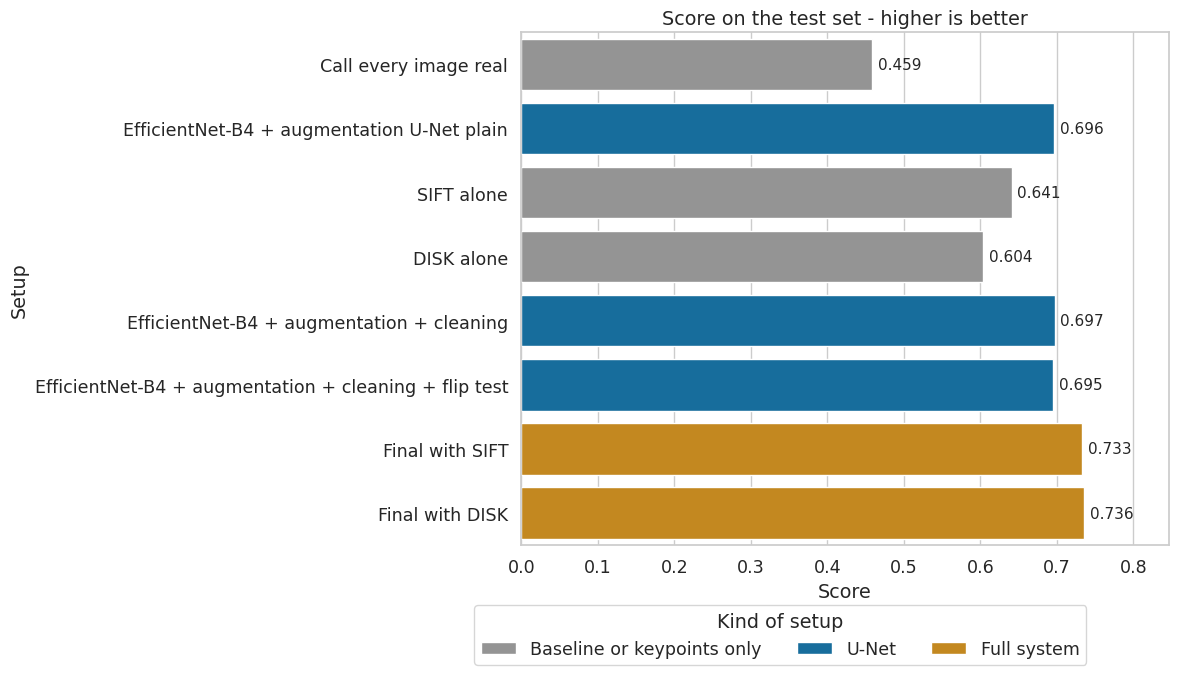

In [39]:
def kind_of(setup):
    """Group each setup for the bar colors."""
    if setup.startswith("Final"):
        return "Full system"
    if "alone" in setup or "real" in setup:
        return "Baseline or keypoints only"
    return "U-Net"


plot_df = results.reset_index().rename(columns={"index": "Setup"})
plot_df["Kind"] = plot_df["Setup"].map(kind_of)
kinds = ["Baseline or keypoints only", "U-Net", "Full system"]

fig, ax = plt.subplots(figsize=(12, 7))
sns.barplot(data=plot_df, y="Setup", x="Score", hue="Kind", hue_order=kinds,
            palette=[PALETTE[7], PALETTE[0], PALETTE[1]], dodge=False, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=4, fontsize=11)
ax.set_xlim(0, results["Score"].max() * 1.15)
ax.set_title("Score on the test set - higher is better")
ax.set_xlabel("Score")
ax.set_ylabel("Setup")
ax.legend(title="Kind of setup", loc="upper center",
          bbox_to_anchor=(0.4, -0.1), ncol=3)
plt.tight_layout()
plt.savefig("plot4_test_scores.png", dpi=150, bbox_inches="tight")
plt.show()

### Plot 5: fakes caught and false alarms
A good system catches many fakes while flagging very few real images. Fakes caught is a percent
of the fake test images and false alarms is a percent of the real ones. The false alarm bars
are striped so they can be told apart without color.

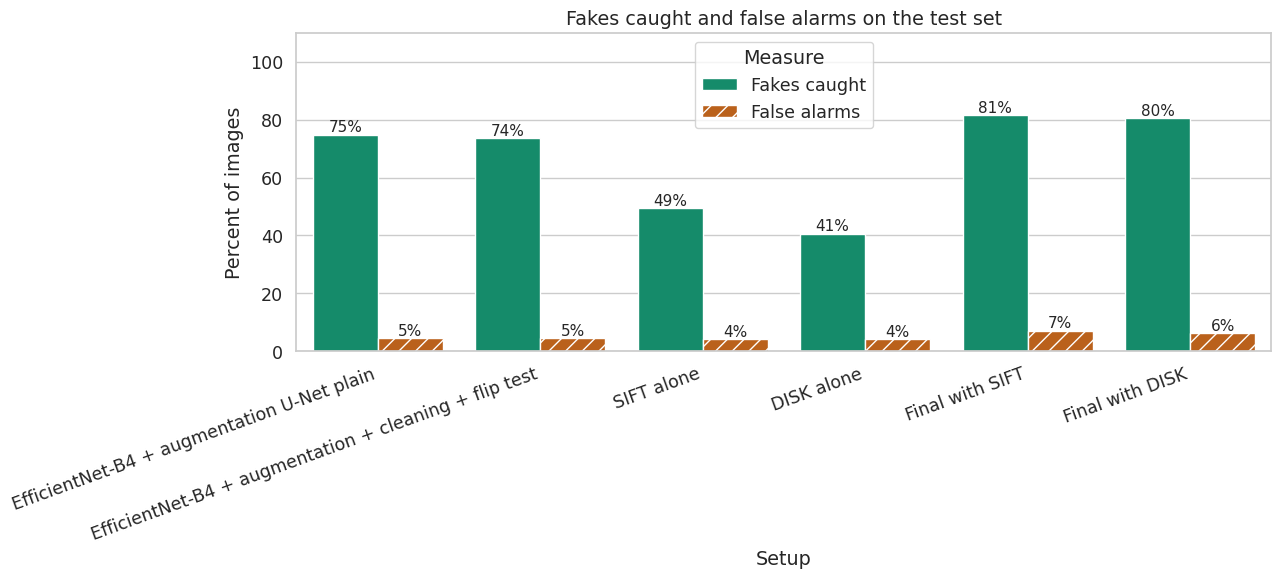

In [40]:
show = [f"{best_name} U-Net plain", f"{best_name} + cleaning + flip test",
        "SIFT alone", "DISK alone", "Final with SIFT", "Final with DISK"]
percents = results.loc[show, ["Fakes caught", "False alarms"]] * 100
# reshape to one row per setup and measure, the form seaborn needs
long = percents.reset_index().melt(id_vars="index", var_name="Measure",
                                   value_name="Percent")

fig, ax = plt.subplots(figsize=(13, 6))
sns.barplot(data=long, x="index", y="Percent", hue="Measure", ax=ax,
            palette=[PALETTE[2], PALETTE[3]])
for bar in ax.containers[1]:
    bar.set_hatch("//")          # stripes, so color is not the only cue
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f%%", fontsize=11)
ax.set_title("Fakes caught and false alarms on the test set")
ax.set_xlabel("Setup")
ax.set_ylabel("Percent of images")
ax.set_ylim(0, 110)
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
# build the legend from the bars so it shows the stripes
ax.legend(handles=ax.containers[:2], labels=["Fakes caught", "False alarms"],
          title="Measure")
plt.tight_layout()
plt.savefig("plot5_caught_and_false_alarms.png", dpi=150, bbox_inches="tight")
plt.show()

### Choosing the keypoint method for the final answer
The final system uses the keypoint method that has the higher validation score in the full
system. The choice is made on the validation images and not on the test images.

In [41]:
# the keypoint method is chosen on the validation images, not the test images
FINAL = max(METHODS, key=lambda m: score(val_idx, final_masks(
    val_idx, val_probs, val_fake, CFG, m, KP_MIN[m]))["score"])

### Plot 6: examples from the test set
The examples are not picked at random. They are the first two fake test images with at least 8
matched pairs, then the first other fake in the list, and the first real image that the system
left unmarked. A real image and its fake version share a case ID. Here the real example in the
last row is the original of the fake in the third row.

In [42]:
# where[k] is the position of image k in the test predictions
where = {k: i for i, k in enumerate(test_idx)}
# final_test[k] is the final mask of test image k
final_test = dict(zip(test_idx, rows[f"Final with {FINAL}"]))
# the examples: first the two fakes with at least 8 matched pairs. This
# cutoff is only for the picture, the system itself uses KP_MIN
fakes = [k for k in test_idx if LABELS[k] == 1 and KP[FINAL][k][1] >= 8][:2]
# then the first other fake in test order, so there are three fakes
fakes += [k for k in test_idx
          if LABELS[k] == 1 and k not in fakes][:3 - len(fakes)]
# and the first real image that the system left unmarked
reals = [k for k in test_idx if LABELS[k] == 0 and not final_test[k].any()][:1]
show_k = fakes + reals

Each row is one test image. From left to right, the columns show the image, the true mask,
the U-Net mask after cleaning and before the fake check, the keypoint matches with a line
joining each copy to its source, and the final answer. At most 40 lines are drawn per image to
keep the picture readable. Every picture is shown at 512 by 512, so some look squeezed.

In the second row the U-Net finds only one of the two cobs, and the DISK matches add the other
one. No false alarm is shown here, although 15 of the 238 real test images are flagged.

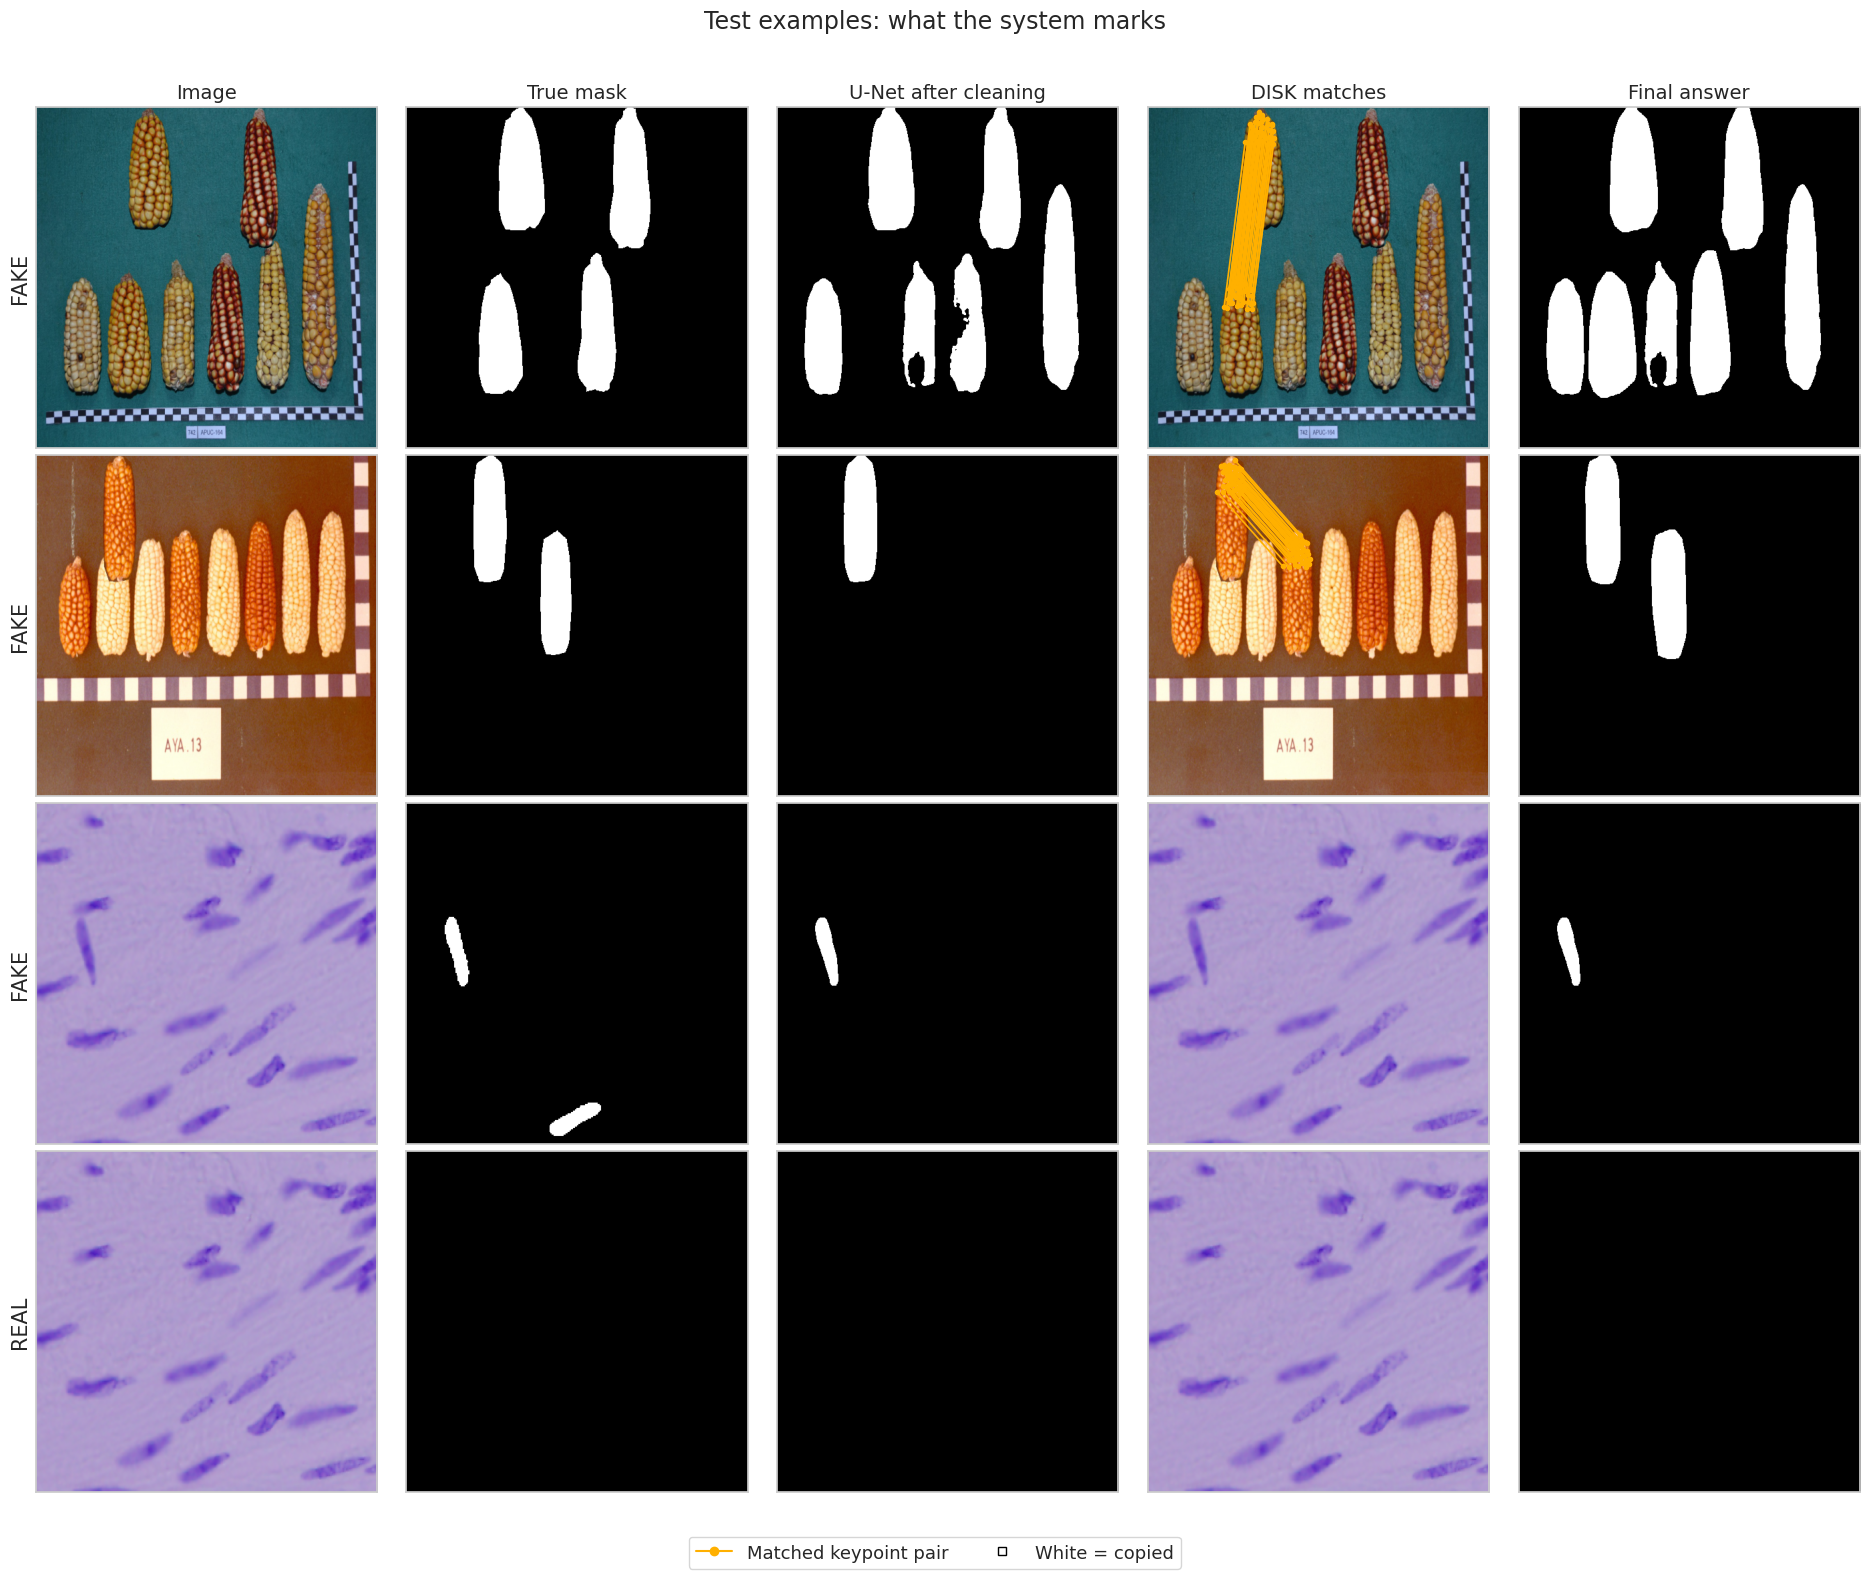

In [43]:
titles = ["Image", "True mask", "U-Net after cleaning", f"{FINAL} matches",
          "Final answer"]

fig, ax = plt.subplots(len(show_k), 5, figsize=(19, 4 * len(show_k)),
                       squeeze=False)
for r, k in enumerate(show_k):
    # the U-Net mask before the fake check is applied
    unet = clean_mask(test_probs[where[k]], CFG["cutoff"], CFG["min_spot"])
    ax[r, 0].imshow(IMGS[k])
    ax[r, 1].imshow(MASKS[k], cmap="gray", vmin=0, vmax=1)
    ax[r, 2].imshow(unet, cmap="gray", vmin=0, vmax=1)
    ax[r, 3].imshow(IMGS[k])
    # draw at most 40 pairs so the picture stays readable
    for x1, y1, x2, y2 in KP[FINAL][k][2][:40]:
        ax[r, 3].plot([x1, x2], [y1, y2], "o-", color="#FFB000", lw=1.2, ms=3)
    ax[r, 4].imshow(final_test[k], cmap="gray", vmin=0, vmax=1)
    ax[r, 0].set_ylabel("FAKE" if LABELS[k] == 1 else "REAL", fontsize=15)
for c, title in enumerate(titles):
    ax[0, c].set_title(title, fontsize=14)
for a in ax.flat:
    a.set_xticks([])
    a.set_yticks([])
    a.grid(False)
legend = [Line2D([0], [0], color="#FFB000", marker="o",
                 label="Matched keypoint pair"),
          Line2D([0], [0], color="white", marker="s", mfc="white",
                 mec="black", ls="", label="White = copied")]
fig.legend(handles=legend, loc="lower center", ncol=2, fontsize=13)
fig.suptitle("Test examples: what the system marks", fontsize=17)
plt.tight_layout(rect=(0, 0.04, 1, 0.97))
plt.savefig("plot6_examples.png", dpi=120, bbox_inches="tight")
plt.show()

## 16. Summary numbers
The main numbers used in the write-up below, printed in one place.

In [44]:
print(f"Train / validation / test: "
      f"{len(train_idx)} / {len(val_idx)} / {len(test_idx)}")
for name, h in hists.items():
    b = int(np.argmax(h["val_score"]))
    print(f"{name}: best epoch {b + 1} of {len(h['val_score'])} "
          f"with validation score {h['val_score'][b]:.3f}")
print("Best model:", best_name)
print("Settings:", CFG)
print("Keypoint minimums:", KP_MIN)
print("Best keypoint method in the full system:", FINAL)
print(results.round(3).to_string())

Train / validation / test: 4142 / 515 / 519
ResNet-34: best epoch 19 of 20 with validation score 0.635
EfficientNet-B4: best epoch 12 of 18 with validation score 0.706
EfficientNet-B4 + augmentation: best epoch 27 of 30 with validation score 0.734
Best model: EfficientNet-B4 + augmentation
Settings: {'cutoff': 0.4, 'min_spot': 0, 'gate': 0.5}
Keypoint minimums: {'SIFT': 30, 'DISK': 20}
Best keypoint method in the full system: DISK
                                                       Score  Fakes caught  False alarms  Mask F1
Call every image real                                  0.459         0.000         0.000    0.000
EfficientNet-B4 + augmentation U-Net plain             0.696         0.747         0.046    0.478
SIFT alone                                             0.641         0.495         0.042    0.373
DISK alone                                             0.604         0.406         0.042    0.304
EfficientNet-B4 + augmentation + cleaning              0.697         0.747 

## Results

### Were you able to implement the solution you described?
Yes, with two swaps that are listed below. I implemented the U-Net segmentation model from my
proposal, with a pretrained encoder,
BCE and Dice loss, a pass mark and removal of small spots. It trains from start to finish in
this notebook and produces a mask for any image.

On top of that I added the changes described at the start of the notebook: a second output for
the whole image, augmentation, a stronger encoder, the flip test and keypoint matching with SIFT
and DISK. The two things from my proposal that I did not build are the DINOv2 encoder and
LightGlue matching. I used EfficientNet-B4 as the encoder and DISK as a learned way to find
keypoints, for the reasons given at the start.

### Does your solution adequately address your real-world problem?
Partly. It works as a screening tool, not as a judge. The system catches 80% of the fake test
images while wrongly flagging about 6% of the real ones, so it can point a reviewer to the
suspicious images and regions in a large set of figures. It still misses about 1 in 5 fakes
and flags some real images, so a person has to check what it finds.

About half of my test images are fake. In real papers fakes should be much rarer, so most of
the images the system flags there would turn out to be real. That is one more reason to use it
only as a first filter.

The masks have limits too. The mask F1 is 0.565, and that average counts every missed fake as 0.
On the fakes the system does catch, the average overlap F1 is about 0.70. So it usually finds the
copied area but does not outline it exactly. Plot 6 shows two weaknesses. When an image is full
of objects that look alike, such as the corn cobs in the first row, the U-Net also marks cobs
that were not copied. The system also sometimes finds only one side of a copy, like in the
third row, where one of the two cells is missed.

### What metrics did you measure and what values did you achieve?
All values are measured on the 519 test images, which were never used for training or for
choosing settings. The four measures are defined in section 8.

| Setup | Score | Fakes caught | False alarms | Mask F1 |
|---|---|---|---|---|
| Call every image real | 0.459 | 0% | 0% | 0.000 |
| U-Net plain | 0.696 | 75% | 5% | 0.478 |
| U-Net + cleaning | 0.697 | 75% | 5% | 0.479 |
| U-Net + cleaning + flip test | 0.695 | 74% | 5% | 0.476 |
| SIFT alone | 0.641 | 49% | 4% | 0.373 |
| DISK alone | 0.604 | 41% | 4% | 0.304 |
| Final with SIFT | 0.733 | 81% | 7% | 0.568 |
| **Final with DISK** | **0.736** | 80% | 6% | 0.565 |

In this table, U-Net means the EfficientNet-B4 model trained with augmentation. The last row is
the final system.

What these numbers show:
- **Overall.** The final system scores 0.736. Calling every image real scores 0.459.
- **Encoder.** The best validation score went from 0.635 with ResNet-34 to 0.706 with
  EfficientNet-B4.
- **Augmentation and longer training.** The final model reached a validation score of 0.734,
  with its best epoch at 27 of 30. This gain is a mix of two things, because the final run also
  trained for longer. After 18 epochs the best scores of the two EfficientNet-B4 models were
  about level, at 0.712 with augmentation and 0.706 without. The difference is that the model
  without augmentation had stopped improving after epoch 12, while the one with augmentation
  kept improving. On the test images, U-Net plain went from 0.664 in the earlier run to 0.696.
- **Keypoint matching.** This was the biggest gain after training. Adding the DISK mask to the
  U-Net raised the score from 0.695 to 0.736, the share of fakes caught from 74% to 80% and the
  mask F1 from 0.476 to 0.565. The price was a small rise in false alarms, from 4.6% to 6.3%,
  which is 11 and then 15 of the 238 real test images.
- **SIFT and DISK.** Inside the full system the two are too close to call, at 0.733 and 0.736
  on the test images. The code uses DISK for the final answer because it had the higher
  validation score in the full system. On its own, SIFT is the stronger of the two.
- **What did not help.** Cleaning and the flip test made almost no difference here. The grid
  search chose not to remove any small spots, and the scores of 0.696, 0.697 and 0.695 are the
  same within noise. I left both steps in the notebook so the reader can see that I tested them.
- **Settings chosen on validation.** A pass mark of 0.4, a fake check of 0.5, and a DISK mask
  that is added when it has at least 20 matches.

A few things to keep in mind when reading these numbers:
- The test set has 519 images, so a difference of a few thousandths means nothing. I did not
  measure how much the scores change with a different split or a different random seed.
- The tuned settings scored 0.742 on the validation images and 0.695 on the test images. Tuning
  explains little of this gap, because the plain model already scored 0.734 on validation and
  0.696 on test. The best epoch was picked on the validation images, and two sets of about 500
  images also differ by chance. That is why I report the test numbers.
- During development I also scored earlier versions of the system on these test images. They
  scored 0.640 at my progress update and 0.699 on November 23. Because of that the final number
  can be slightly optimistic.
- The scores are measured on the 512 by 512 masks, not on the images at their original size.

### How this compares to the top teams
According to a published summary of the top solutions, the top teams built on the same two
ingredients I ended up with, a model that looks at the image and keypoint matching, but went
further. The winning team first detected the panels inside each figure and then matched them
against each other with LightGlue, a learned matcher. The 2nd and 3rd place teams relied on
SIFT. The 2nd place team used a very low contrast threshold and the 3rd place team used CLAHE,
which are the two ideas I adopted for my SIFT step.

My scores cannot be compared directly with the competition leaderboard. The official metric
scores every copied region separately on a hidden test set, while my score is per image on my
own test split.

Sources:
- Competition page: https://www.kaggle.com/competitions/recodai-luc-scientific-image-forgery-detection
- Summary of the top solutions by yuki16: https://zenn.dev/yuki16/articles/27a60b48fa1e11

### Plots in this notebook
1. **Data overview:** image sizes and how much of each fake is copied
2. **Training and validation loss** for each model
3. **Validation score** after each epoch for each model
4. **Test score** of every setup
5. **Fakes caught and false alarms** for the main setups
6. **Examples** from the test set with the true mask, the U-Net mask, the keypoint matches and the final answer

## Conclusion
I built a system that finds copy-move forgeries in research images by combining a U-Net with
keypoint matching. On test images it had never seen, it scores 0.736, catches 80% of the fakes
and wrongly flags 6% of the real images. That is well above the baseline of 0.459 and above the
0.640 I had at my progress update. The gains came from a stronger encoder, from training longer
with augmentation and from keypoint matching.

If I continued this project, I would work on three things:
1. Detect the separate panels of each figure and match them against each other, like the winning
   team did. That would also make learned matchers such as LightGlue usable.
2. Train on larger images or on crops, because resizing every image to 512 pixels loses detail
   in small copies.
3. Reduce the over-marking in images with many similar objects. One idea is to drop a U-Net
   region that has no keypoint match when other regions in the same image do have one.